In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data=pd.read_csv('household_power_consumption.csv')
data

,index,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,0,1/1/07,0:00:00,2.58,0.136,241.97,10.6,0,0,0.0
1,1,1/1/07,0:01:00,2.552,0.1,241.75,10.4,0,0,0.0
2,2,1/1/07,0:02:00,2.55,0.1,241.64,10.4,0,0,0.0
3,3,1/1/07,0:03:00,2.55,0.1,241.71,10.4,0,0,0.0
4,4,1/1/07,0:04:00,2.554,0.1,241.98,10.4,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...
260635,260635,30/6/2007,23:55:00,2.88,0.36,239.01,12,0,0,18.0
260636,260636,30/6/2007,23:56:00,2.892,0.358,238.86,12.2,0,0,17.0
260637,260637,30/6/2007,23:57:00,2.882,0.28,239.05,12,0,0,18.0
260638,260638,30/6/2007,23:58:00,2.66,0.29,238.98,11.2,0,0,18.0


In [3]:
# # Step 1: Fix single-digit days and months
# sample_dates_before = data['Date'].head(20)
# print("Sample Dates before fixing:")
# print(sample_dates_before)
# data['Date'] = data['Date'].apply(lambda x: '/'.join([part.zfill(2) if i < 2 else part for i, part in enumerate(x.split('/'))]))

# # Step 2: Fix two-digit years (e.g., 07 -> 2007)
# data['Date'] = data['Date'].apply(lambda x: x[:6] + '20' + x[6:] if len(x.split('/')[2]) == 2 else x)

# # Sample of dates before and after fixing
# sample_dates_after = data['Date'].head(20)

# print("Sample Dates after fixing:")
# print(sample_dates_after)


In [4]:
data['Global_active_power'] = pd.to_numeric(data['Global_active_power'], errors='coerce')
data['Global_reactive_power'] = pd.to_numeric(data['Global_reactive_power'], errors='coerce')
data['Voltage'] = pd.to_numeric(data['Voltage'], errors='coerce')
data['Global_intensity'] = pd.to_numeric(data['Global_intensity'], errors='coerce')
data['Sub_metering_1'] = pd.to_numeric(data['Sub_metering_1'], errors='coerce')
data['Sub_metering_2'] = pd.to_numeric(data['Sub_metering_2'], errors='coerce')
data['Sub_metering_3'] = pd.to_numeric(data['Sub_metering_3'], errors='coerce')
data.drop(['index'],axis=1,inplace=True)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260640 entries, 0 to 260639
Data columns (total 9 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Date                   260640 non-null  object 
 1   Time                   260640 non-null  object 
 2   Global_active_power    256869 non-null  float64
 3   Global_reactive_power  256869 non-null  float64
 4   Voltage                256869 non-null  float64
 5   Global_intensity       256869 non-null  float64
 6   Sub_metering_1         256869 non-null  float64
 7   Sub_metering_2         256869 non-null  float64
 8   Sub_metering_3         256869 non-null  float64
dtypes: float64(7), object(2)
memory usage: 17.9+ MB


In [5]:
# # Convert Date and Time columns into a single datetime column
# data['Datetime'] = pd.to_datetime(data['Date'] + ' ' + data['Time'], format='%d/%m/%Y %H:%M:%S', dayfirst=True)

# # Drop the original Date and Time columns

# # Check the result
# data.head()


In [6]:
# بررسی تعداد مقادیر گمشده در هر ستون
missing_values = data.isnull().sum()

# نمایش مقادیر گمشده
missing_values[missing_values > 0]


Global_active_power      3771
Global_reactive_power    3771
Voltage                  3771
Global_intensity         3771
Sub_metering_1           3771
Sub_metering_2           3771
Sub_metering_3           3771
dtype: int64

In [7]:
data.dropna(inplace=True)
data.reset_index(drop=True, inplace=True)

data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 256869 entries, 0 to 256868
Data columns (total 9 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Date                   256869 non-null  object 
 1   Time                   256869 non-null  object 
 2   Global_active_power    256869 non-null  float64
 3   Global_reactive_power  256869 non-null  float64
 4   Voltage                256869 non-null  float64
 5   Global_intensity       256869 non-null  float64
 6   Sub_metering_1         256869 non-null  float64
 7   Sub_metering_2         256869 non-null  float64
 8   Sub_metering_3         256869 non-null  float64
dtypes: float64(7), object(2)
memory usage: 17.6+ MB


In [8]:
data=data.groupby(['Date']).sum()
data

,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Date,,,,,,,,
1/1/07,0:00:000:01:000:02:000:03:000:04:000:05:000:06...,2749.004,148.166,345785.73,11400.4,0.0,352.0,5880.0
1/2/07,0:00:000:01:000:02:000:03:000:04:000:05:000:06...,1824.760,150.264,346164.68,7678.8,1170.0,386.0,13145.0
1/3/07,0:00:000:01:000:02:000:03:000:04:000:05:000:06...,517.564,107.628,347502.82,2172.8,0.0,316.0,1980.0
1/4/07,0:00:000:01:000:02:000:03:000:04:000:05:000:06...,2785.952,202.552,345635.26,11735.2,4629.0,5401.0,19509.0
1/5/07,0:00:000:01:000:02:000:03:000:04:000:05:000:06...,1663.858,181.608,337937.33,7305.6,4005.0,995.0,8546.0
...,...,...,...,...,...,...,...,...
9/2/07,0:00:000:01:000:02:000:03:000:04:000:05:000:06...,1620.198,158.066,348106.24,6807.2,0.0,3045.0,9770.0
9/3/07,0:00:000:01:000:02:000:03:000:04:000:05:000:06...,1272.612,119.238,346879.39,5373.0,1093.0,345.0,8631.0
9/4/07,0:00:000:01:000:02:000:03:000:04:000:05:000:06...,1000.920,160.110,346392.70,4283.4,2667.0,514.0,3801.0


In [9]:
# Time - Series Graph
def time_series(df,column,x_axis,title=''):
    n_rows = len(column)
    fig, axes = plt.subplots(nrows=n_rows, figsize=(10, 30))
    fig.tight_layout(h_pad=5)

    for i in range(n_rows):

        ax = axes[i]
        sns.lineplot(data=df, x=x_axis, y=column[i], ax=ax)
        ax.set_title(f'{column[i]} {title}')

    return plt.show()

In [10]:
float_cols = ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

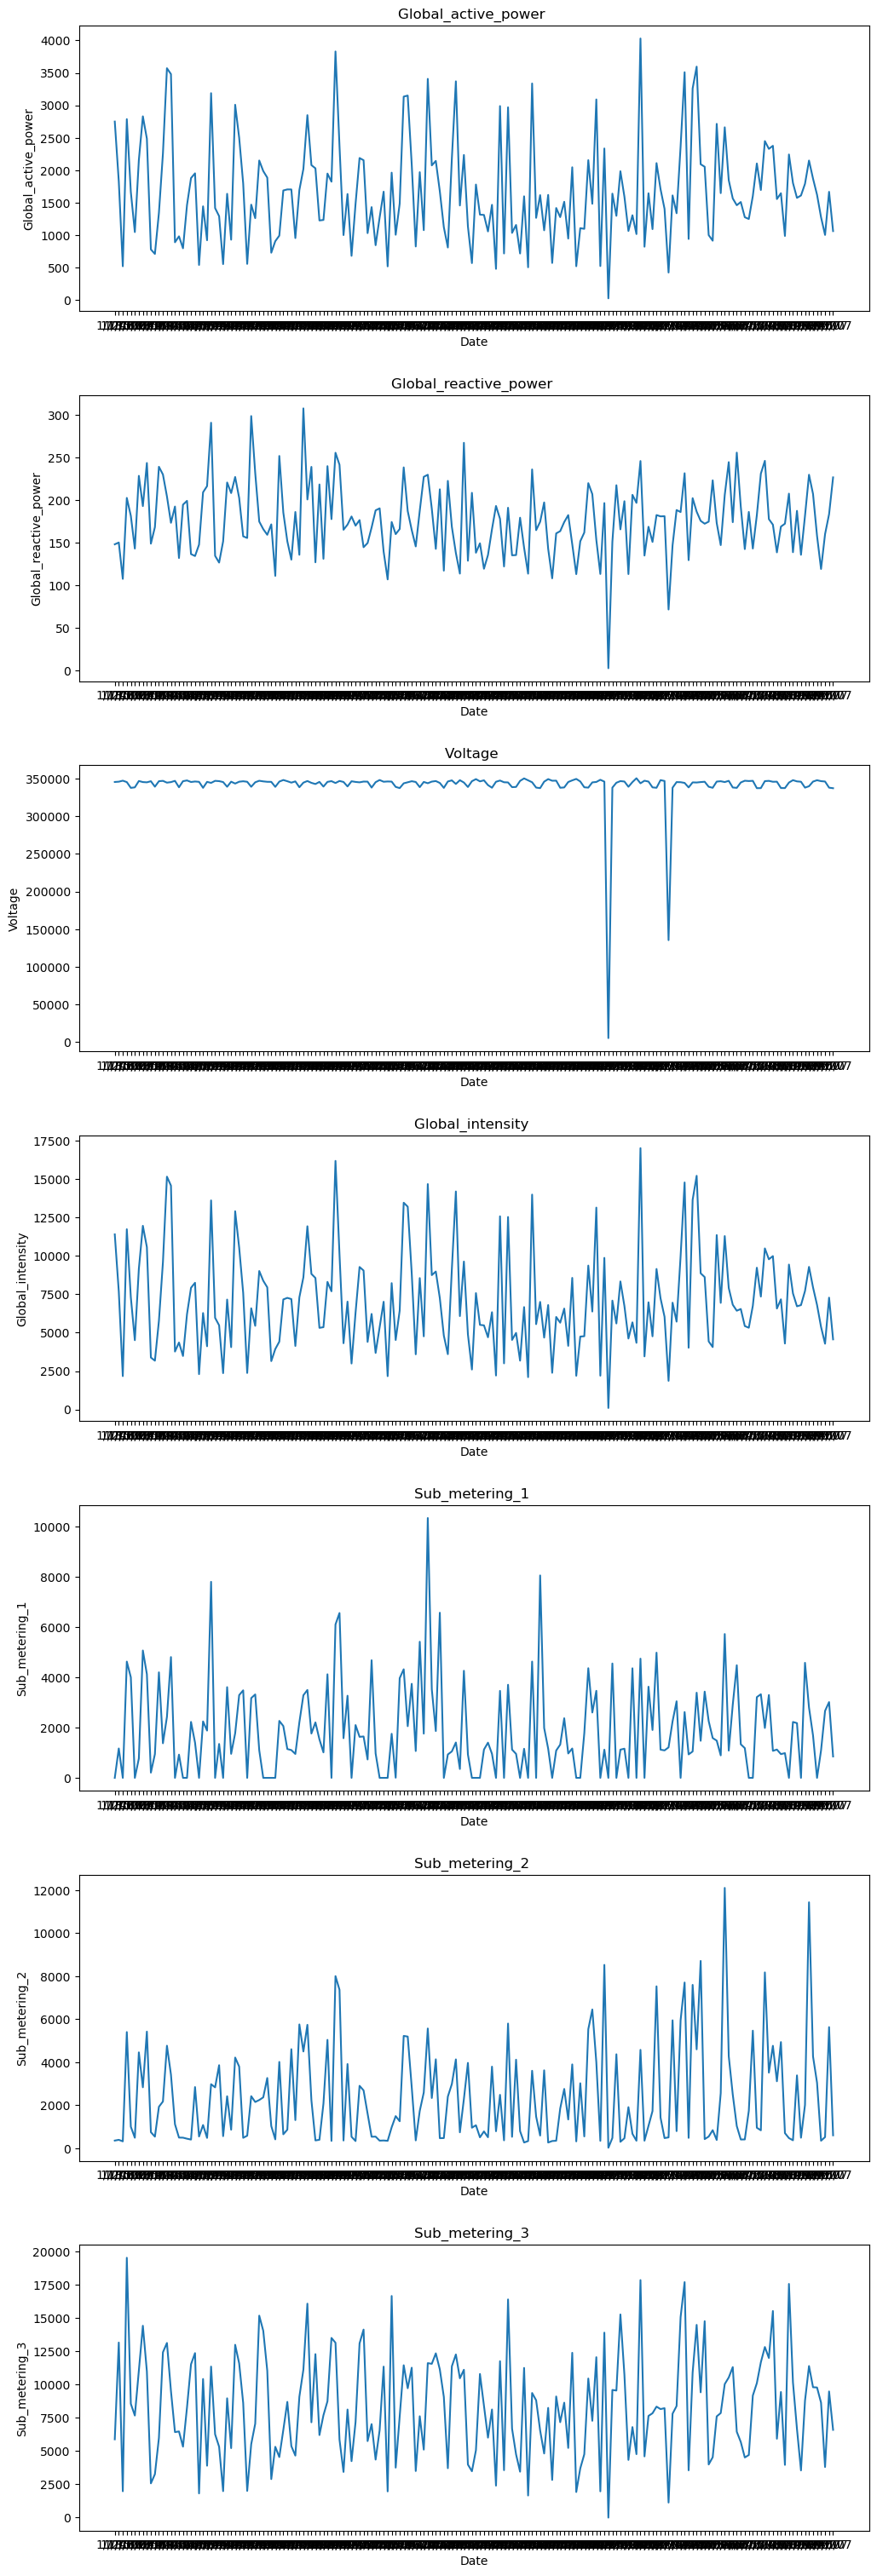

In [11]:
by_date = time_series(data,float_cols,'Date')

In [12]:
def boxpl_graph(df,column, title=''):
    n_rows = len(column)
    fig, axes = plt.subplots(nrows=n_rows, figsize=(10, 20))
    fig.tight_layout()

    for i in range(n_rows):
        ax = axes[i]
        sns.boxplot(data=df[column[i]], ax=ax, orient='h')

        ax.set_title(f'{column[i]} {title}')
    return plt.show()

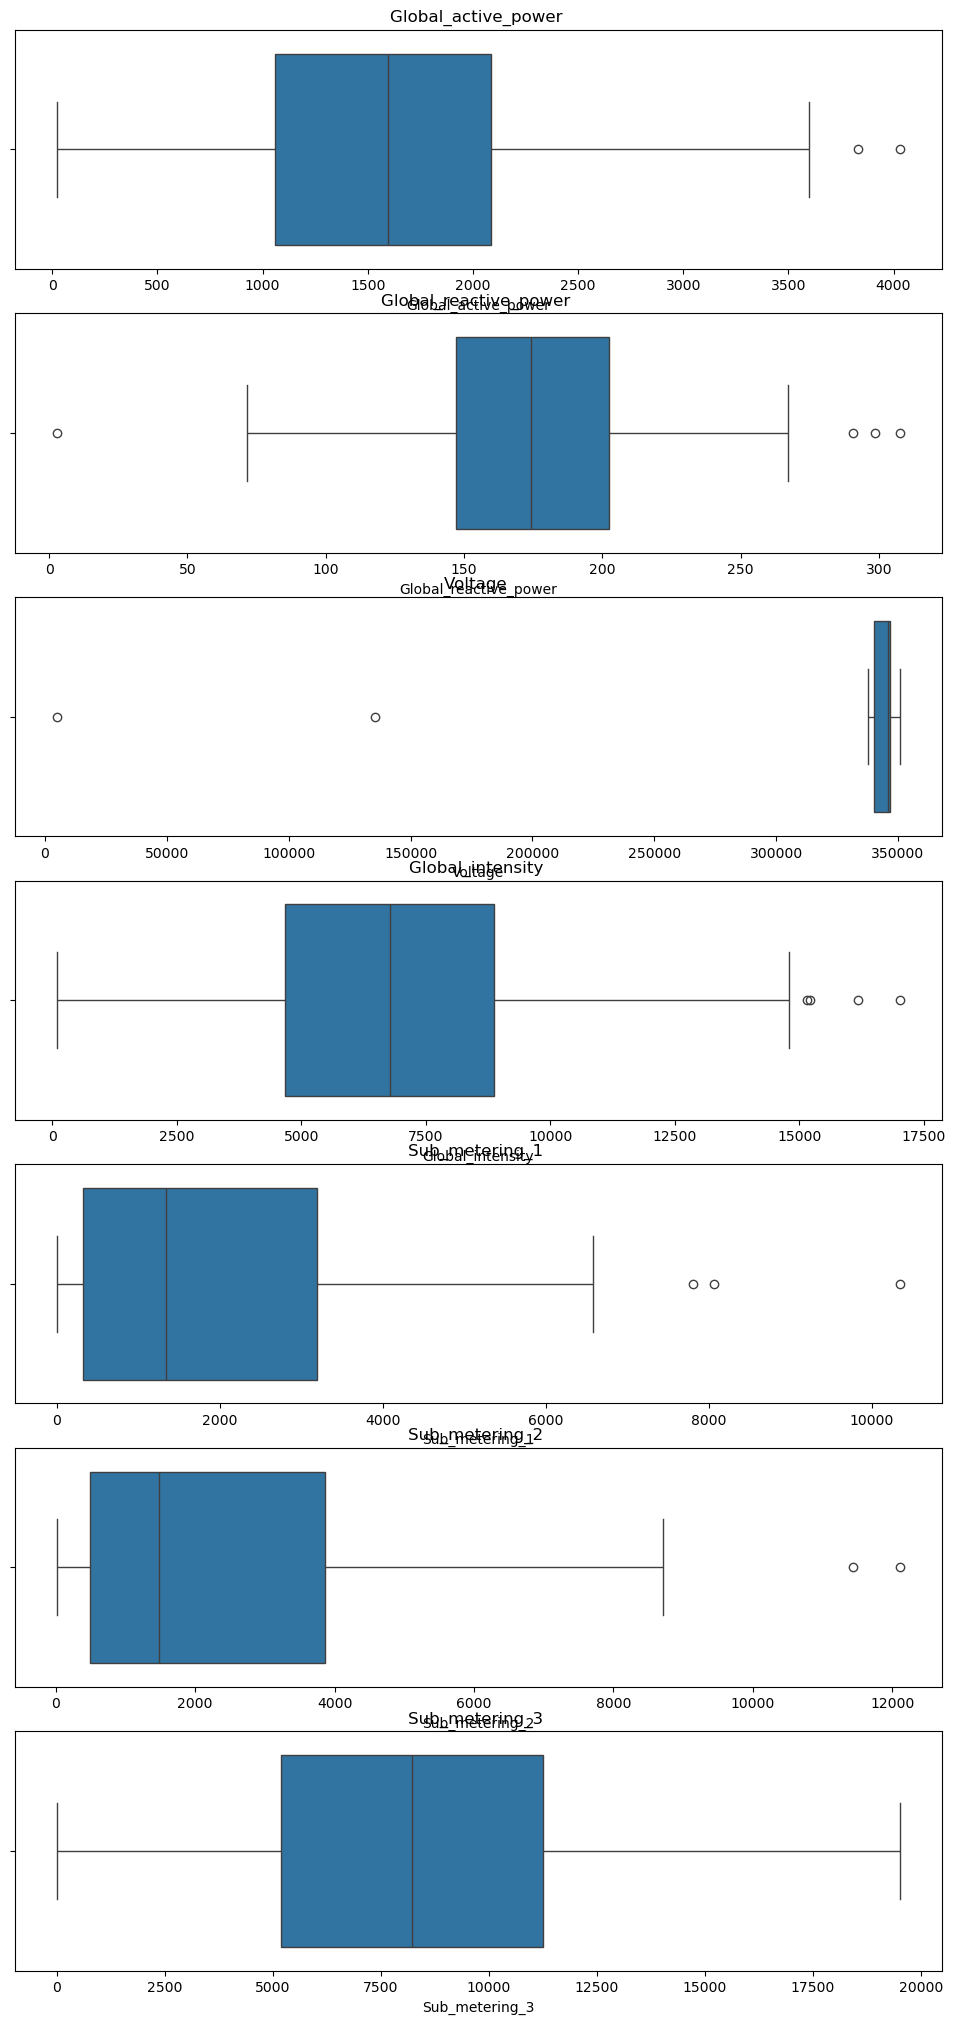

In [13]:
box_plot = boxpl_graph(data,float_cols)

In [14]:
def remove_outlier_iqr(data):
    q1 =data.quantile(0.25)
    q2=data.quantile(0.75)
    iqr = q2-q1 
    data_final=data[~((data<(q1 -1.5*iqr)) | (data>(q2+1.5*iqr)))]
    return data_final

In [15]:
for x in float_cols:
    data[x] = remove_outlier_iqr(data[x])

In [16]:
data.reset_index(inplace=True)

In [17]:
data.columns

Index(['Date', 'Time', 'Global_active_power', 'Global_reactive_power',
       'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='object')

In [18]:
data = data.drop(columns=['Time'])
data

,Date,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,1/1/07,2749.004,148.166,345785.73,11400.4,0.0,352.0,5880.0
1,1/2/07,1824.760,150.264,346164.68,7678.8,1170.0,386.0,13145.0
2,1/3/07,517.564,107.628,347502.82,2172.8,0.0,316.0,1980.0
3,1/4/07,2785.952,202.552,345635.26,11735.2,4629.0,5401.0,19509.0
4,1/5/07,1663.858,181.608,337937.33,7305.6,4005.0,995.0,8546.0
...,...,...,...,...,...,...,...,...
175,9/2/07,1620.198,158.066,348106.24,6807.2,0.0,3045.0,9770.0
176,9/3/07,1272.612,119.238,346879.39,5373.0,1093.0,345.0,8631.0
177,9/4/07,1000.920,160.110,346392.70,4283.4,2667.0,514.0,3801.0
178,9/5/07,1665.736,183.484,338218.16,7280.8,3018.0,5631.0,9474.0


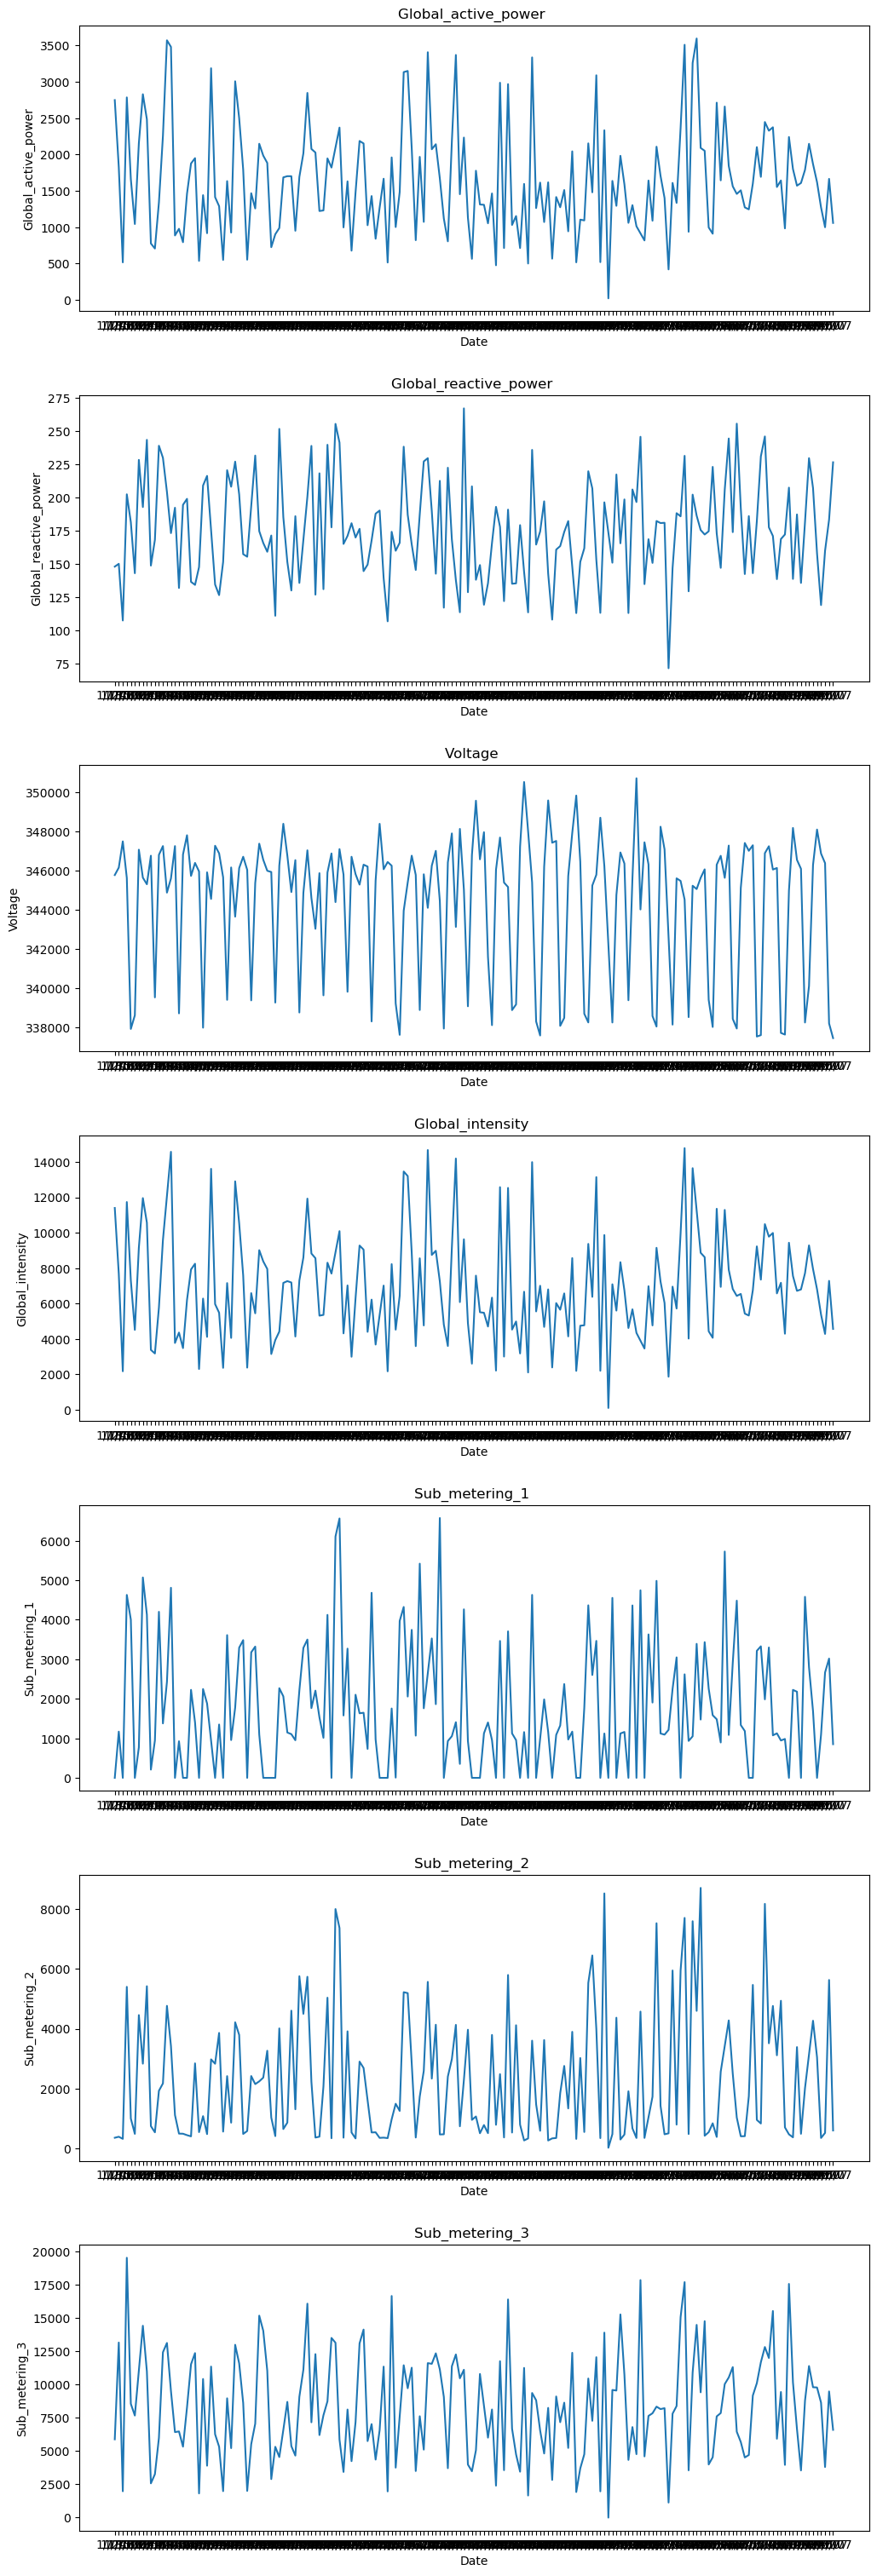

In [19]:
by_date_no_outl = time_series(data,float_cols,'Date')